In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_csv("../data/Bengaluru_House_Data.csv")

# Display settings
pd.set_option("display.max_columns", None)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [32]:

# Dataset information
df.info()

# Statistical summary
display(df.describe(include="all").T)

# Column names
print("Columns:", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 1.6 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area_type,13320,4,Super built-up Area,8790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,13320,81,Ready To Move,10581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,13319,1305,Whitefield,540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,13304,31,2 BHK,5199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
society,7818,2688,GrrvaGr,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sqft,13320,2117,1200,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bath,13247.0,NaN,NaN,NaN,2.69261,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,NaN,NaN,NaN,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,NaN,NaN,NaN,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


Columns: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']


In [33]:

print("Missing values:")
print(df.isnull().sum())

print("\nMissing value percentage:")
print((df.isnull().mean() * 100).round(2))

print("\nExact duplicate rows:", df.duplicated().sum())


Missing values:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Missing value percentage:
area_type        0.00
availability     0.00
location         0.01
size             0.12
society         41.31
total_sqft       0.00
bath             0.55
balcony          4.57
price            0.00
dtype: float64

Exact duplicate rows: 529


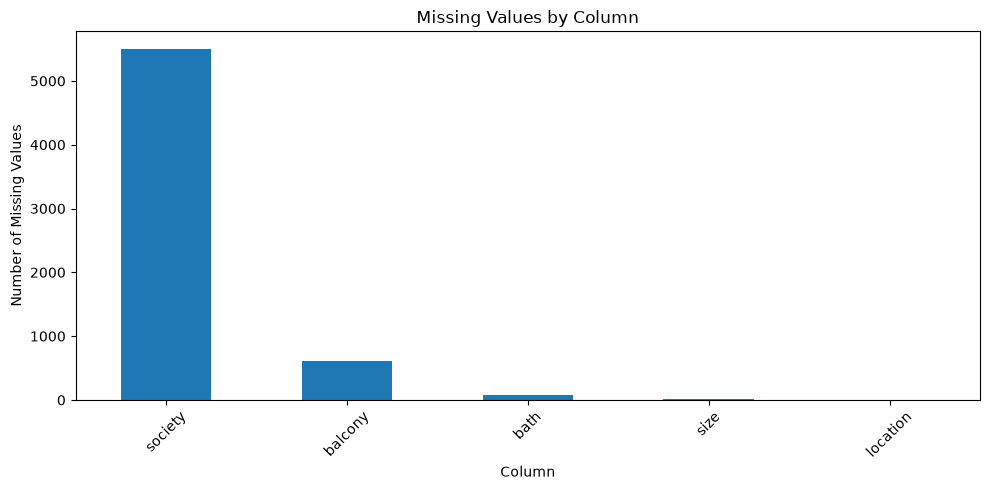

In [34]:

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64


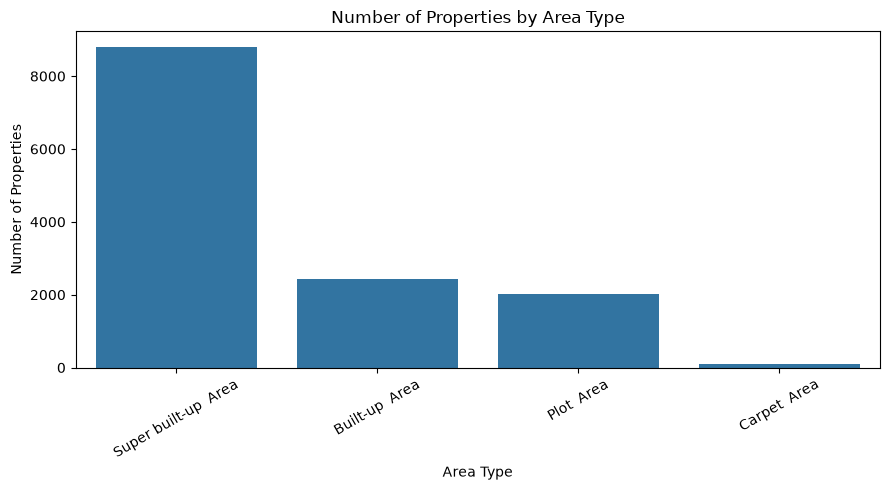

In [35]:

print(df["area_type"].value_counts())

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="area_type", order=df["area_type"].value_counts().index)
plt.title("Number of Properties by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


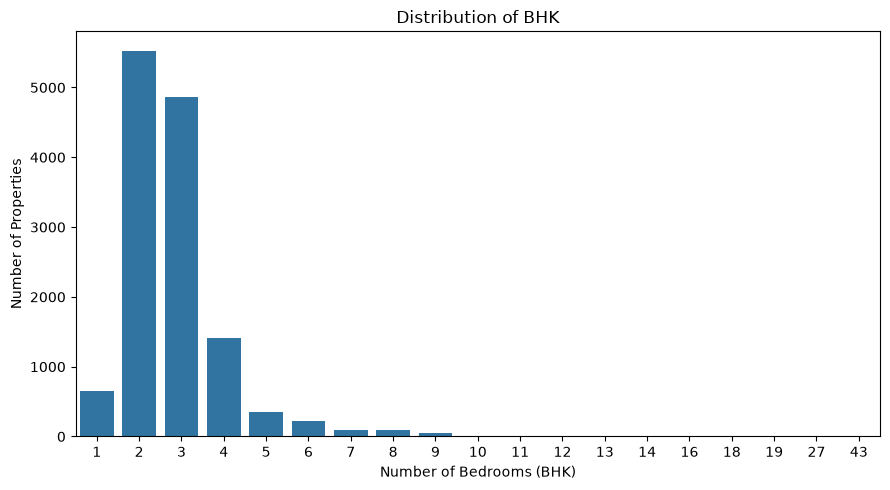

In [36]:

bhk_df = df["size"].dropna().str.extract(r"(\d+)")[0]
bhk_df = pd.to_numeric(bhk_df, errors="coerce").dropna()

plt.figure(figsize=(9, 5))
sns.countplot(x=bhk_df.astype(int))
plt.title("Distribution of BHK")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()


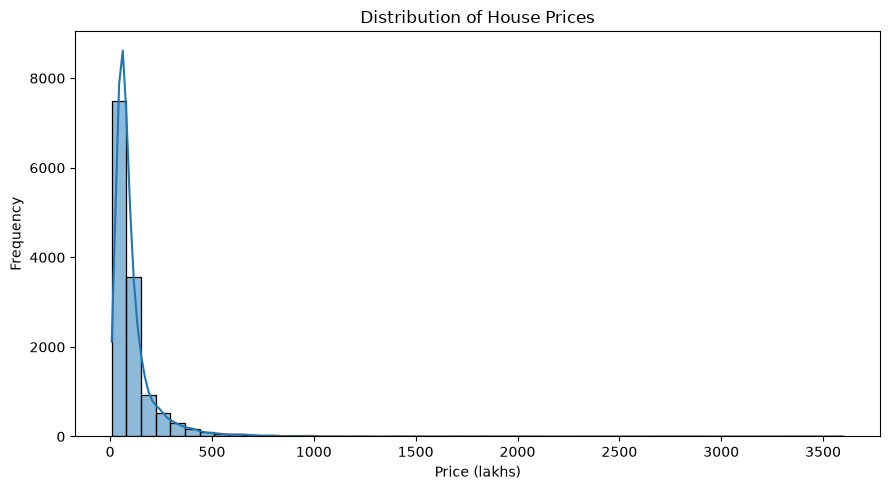

count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64


In [37]:

plt.figure(figsize=(9, 5))
sns.histplot(df["price"].dropna(), bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price (lakhs)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(df["price"].describe())


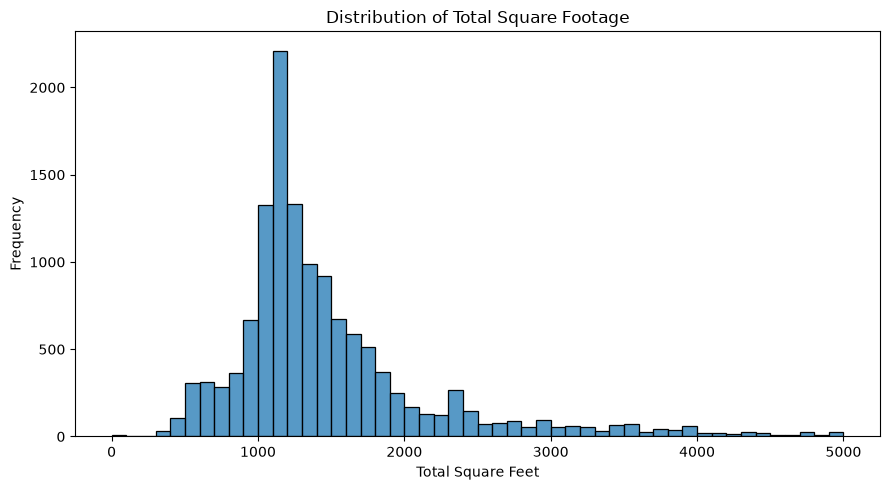

count    13274.000000
mean      1559.626694
std       1238.405258
min          1.000000
25%       1100.000000
50%       1276.000000
75%       1680.000000
max      52272.000000
Name: total_sqft, dtype: float64


In [38]:

def convert_sqft(value):
    value = str(value).strip()

    try:
        if "-" in value:
            low, high = value.split("-", 1)
            return (float(low) + float(high)) / 2

        return float(value)

    except (ValueError, TypeError):
        return np.nan

sqft_values = df["total_sqft"].apply(convert_sqft).dropna()

plt.figure(figsize=(9, 5))
sns.histplot(sqft_values[sqft_values <= 5000], bins=50)
plt.title("Distribution of Total Square Footage")
plt.xlabel("Total Square Feet")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(sqft_values.describe())


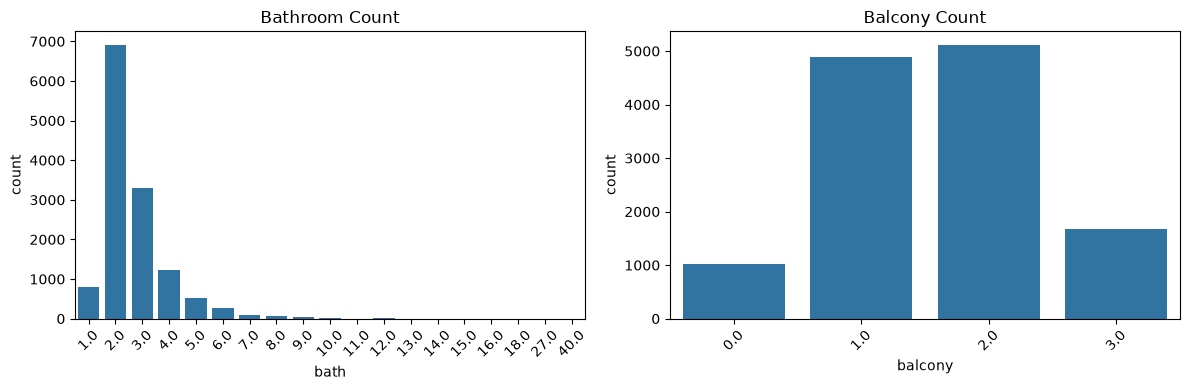

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="bath", ax=axes[0])
axes[0].set_title("Bathroom Count")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="balcony", ax=axes[1])
axes[1].set_title("Balcony Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


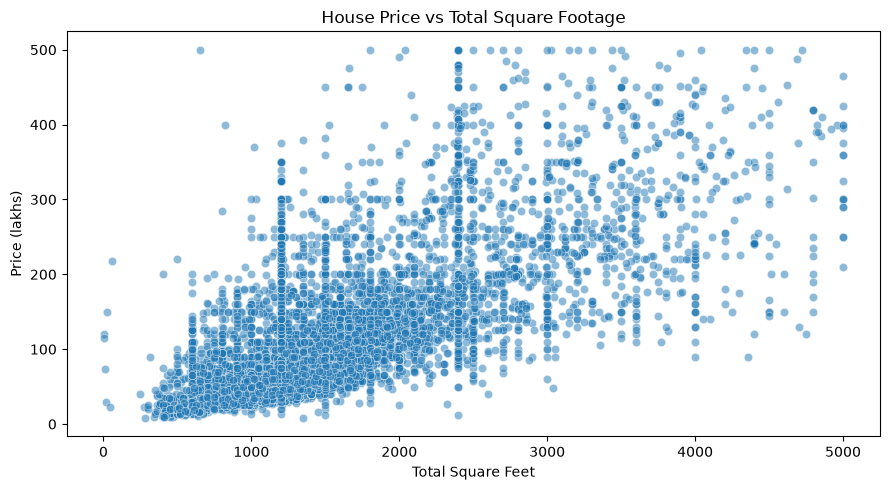

In [40]:

plot_df = pd.DataFrame({
    "total_sqft": df["total_sqft"].apply(convert_sqft),
    "price": df["price"]
}).dropna()

plot_df = plot_df[
    (plot_df["total_sqft"] <= 5000) &
    (plot_df["price"] <= 500)
]

plt.figure(figsize=(9, 5))
sns.scatterplot(data=plot_df, x="total_sqft", y="price", alpha=0.5)
plt.title("House Price vs Total Square Footage")
plt.xlabel("Total Square Feet")
plt.ylabel("Price (lakhs)")
plt.tight_layout()
plt.show()


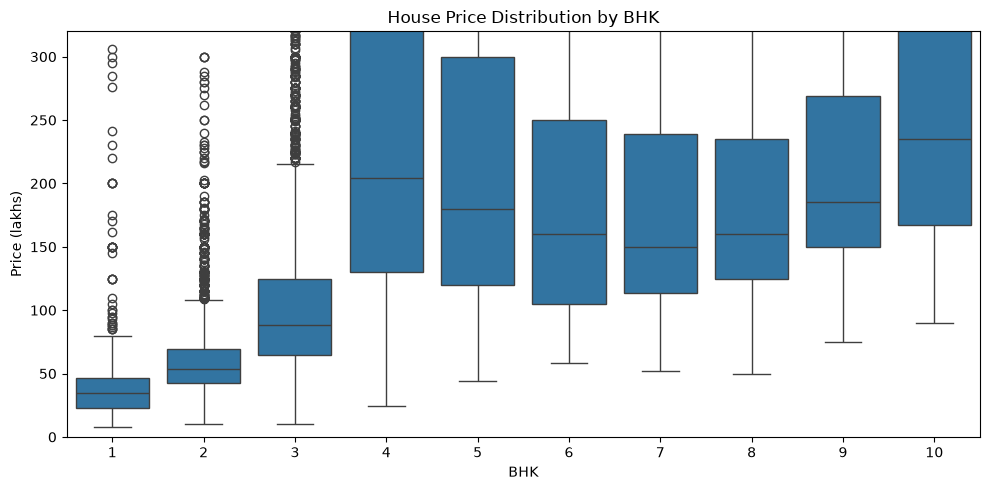

In [41]:

bhk_price_df = df[["size", "price"]].dropna().copy()
bhk_price_df["BHK"] = pd.to_numeric(
    bhk_price_df["size"].str.extract(r"(\d+)")[0],
    errors="coerce"
)
bhk_price_df = bhk_price_df.dropna()
bhk_price_df = bhk_price_df[bhk_price_df["BHK"] <= 10]

plt.figure(figsize=(10, 5))
sns.boxplot(data=bhk_price_df, x="BHK", y="price")
plt.title("House Price Distribution by BHK")
plt.xlabel("BHK")
plt.ylabel("Price (lakhs)")
plt.ylim(0, bhk_price_df["price"].quantile(0.95))
plt.tight_layout()
plt.show()


count    1.325800e+04
mean     7.912634e+03
std      1.064936e+05
min      2.678298e+02
25%      4.271229e+03
50%      5.438331e+03
75%      7.313266e+03
95%      1.528991e+04
99%      2.352027e+04
max      1.200000e+07
Name: price_per_sqft, dtype: float64


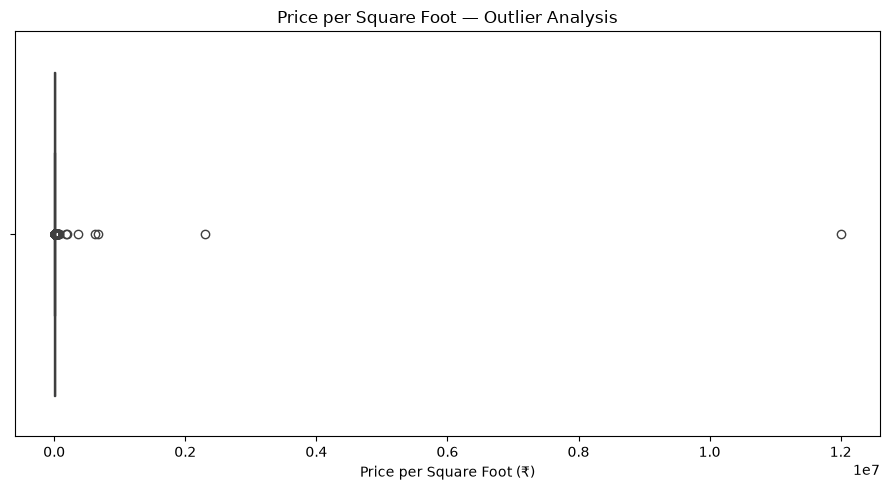

In [42]:

outlier_df = df.copy()

outlier_df["total_sqft"] = outlier_df["total_sqft"].apply(convert_sqft)
outlier_df["BHK"] = pd.to_numeric(
    outlier_df["size"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

outlier_df = outlier_df.dropna(
    subset=["total_sqft", "BHK", "price"]
)

outlier_df = outlier_df[
    (outlier_df["total_sqft"] > 0) &
    (outlier_df["price"] > 0)
].copy()

outlier_df["price_per_sqft"] = (
    outlier_df["price"] * 100000 / outlier_df["total_sqft"]
)

print(outlier_df["price_per_sqft"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
))

plt.figure(figsize=(9, 5))
sns.boxplot(x=outlier_df["price_per_sqft"])
plt.title("Price per Square Foot — Outlier Analysis")
plt.xlabel("Price per Square Foot (₹)")
plt.tight_layout()
plt.show()


count    1.325800e+04
mean     7.912634e+03
std      1.064936e+05
min      2.678298e+02
25%      4.271229e+03
50%      5.438331e+03
75%      7.313266e+03
95%      1.528991e+04
99%      2.352027e+04
max      1.200000e+07
Name: price_per_sqft, dtype: float64


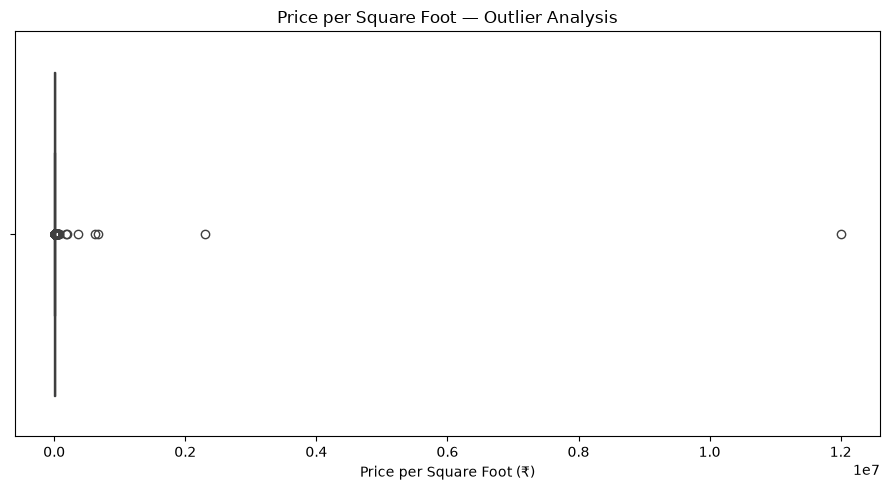

In [43]:

outlier_df = df.copy()

outlier_df["total_sqft"] = outlier_df["total_sqft"].apply(convert_sqft)
outlier_df["BHK"] = pd.to_numeric(
    outlier_df["size"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

outlier_df = outlier_df.dropna(
    subset=["total_sqft", "BHK", "price"]
)

outlier_df = outlier_df[
    (outlier_df["total_sqft"] > 0) &
    (outlier_df["price"] > 0)
].copy()

outlier_df["price_per_sqft"] = (
    outlier_df["price"] * 100000 / outlier_df["total_sqft"]
)

print(outlier_df["price_per_sqft"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
))

plt.figure(figsize=(9, 5))
sns.boxplot(x=outlier_df["price_per_sqft"])
plt.title("Price per Square Foot — Outlier Analysis")
plt.xlabel("Price per Square Foot (₹)")
plt.tight_layout()
plt.show()


In [44]:

clean_df = df.copy()

# Remove unnecessary columns
clean_df.drop(
    columns=["availability", "society"],
    inplace=True
)

# Handle missing values
clean_df["size"] = (
    clean_df["size"]
    .fillna("0")
    .str.split()
    .str[0]
    .astype(int)
)

clean_df["size"] = clean_df["size"].replace(
    0, clean_df["size"].median()
)

clean_df["bath"] = clean_df["bath"].fillna(
    clean_df["bath"].median()
)

clean_df["balcony"] = clean_df["balcony"].fillna(
    clean_df["balcony"].median()
)

clean_df.dropna(inplace=True)

# Convert total_sqft to numeric
clean_df["total_sqft"] = clean_df["total_sqft"].apply(
    convert_sqft
)

clean_df.dropna(subset=["total_sqft"], inplace=True)

# Rename columns
clean_df.rename(
    columns={
        "size": "BHK",
        "price": "price_in_lakhs"
    },
    inplace=True
)

# Clean and group locations
clean_df["location"] = clean_df["location"].str.strip()

location_counts = clean_df["location"].value_counts()
rare_locations = location_counts[
    location_counts <= 10
].index

clean_df["location"] = clean_df["location"].replace(
    rare_locations, "others"
)

# Remove properties with less than 300 sqft per BHK
clean_df = clean_df[
    (clean_df["total_sqft"] / clean_df["BHK"]) >= 300
].copy()

# Calculate price per square foot
clean_df["price_per_sqft"] = (
    clean_df["price_in_lakhs"] * 100000 /
    clean_df["total_sqft"]
)

# Location-wise outlier removal
def remove_location_outliers(data):
    groups = []

    for _, group in data.groupby("location"):
        mean = group["price_per_sqft"].mean()
        std = group["price_per_sqft"].std(ddof=0)

        filtered = group[
            (group["price_per_sqft"] > mean - std) &
            (group["price_per_sqft"] <= mean + std)
        ]

        groups.append(filtered)

    return pd.concat(groups)

clean_df = remove_location_outliers(clean_df)

# BHK-based outlier removal
def remove_bhk_outliers(data):
    exclude = []

    for _, location_df in data.groupby("location"):
        stats = location_df.groupby("BHK")[
            "price_per_sqft"
        ].agg(["mean", "count"])

        for bhk, group in location_df.groupby("BHK"):
            previous_bhk = bhk - 1

            if previous_bhk in stats.index:
                previous = stats.loc[previous_bhk]

                if previous["count"] > 5:
                    exclude.extend(
                        group[
                            group["price_per_sqft"] <
                            previous["mean"]
                        ].index
                    )

    return data.drop(index=exclude)

clean_df = remove_bhk_outliers(clean_df)

# Remove temporary column
clean_df.drop(columns=["price_per_sqft"], inplace=True)

# Reset index
clean_df.reset_index(drop=True, inplace=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())

display(clean_df.head())


Original dataset shape: (13320, 9)
Cleaned dataset shape: (7348, 7)

Missing values:
area_type         0
location          0
BHK               0
total_sqft        0
bath              0
balcony           0
price_in_lakhs    0
dtype: int64


,area_type,location,BHK,total_sqft,bath,balcony,price_in_lakhs
0,Super built-up Area,1st Block Jayanagar,4,2850.0,4.0,1.0,428.0
1,Super built-up Area,1st Block Jayanagar,3,1630.0,3.0,2.0,194.0
2,Super built-up Area,1st Block Jayanagar,3,1875.0,2.0,3.0,235.0
3,Built-up Area,1st Block Jayanagar,3,1200.0,2.0,0.0,130.0
4,Super built-up Area,1st Block Jayanagar,2,1235.0,2.0,2.0,148.0


In [45]:

import os

os.makedirs("../data", exist_ok=True)

clean_df.to_csv(
    "../data/cleaned_bengaluru_house_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("../data/cleaned_bengaluru_house_data.csv")


Cleaned dataset saved successfully!
../data/cleaned_bengaluru_house_data.csv
